# **Linear Regression (Logistic Regression)**

## **Classification**

In [33]:
# Load the dataset
import pandas as pd
diabetes_df = pd.read_csv("diabetes_data_upload.csv")

# Map the categorical values to binary numbers
diabetes_df = diabetes_df.replace({'Yes': 1, 'No': 0, 'Positive': 1, 'Negative': 0, 'Male': 1, 'Female': 0})
X_class = diabetes_df.drop('class', axis=1)
y_class = diabetes_df['class']
y_class = y_class.astype(int)

In [45]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class, y_class, stratify=y_class, test_size=0.2, random_state=42)

In [46]:
from sklearn.preprocessing import RobustScaler

# Scale the features using RobustScaler to reduce the impact of outliers
scaler = RobustScaler()
X_train_class_scaled = scaler.fit_transform(X_train_class)
X_test_class_scaled = scaler.transform(X_test_class)

In [47]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
# Train the logistic regression model
model.fit(X_train_class_scaled, y_train_class)
# Make predictions on the scaled test data
y_pred_class = model.predict(X_test_class_scaled)

In [48]:
# Evaluate the model
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Accuracy: {:03.2f}".format(accuracy_score(y_test_class, y_pred_class)))
print("Confusion Matrix:")
print(confusion_matrix(y_test_class, y_pred_class))
print("Classification Report:")
print(classification_report(y_test_class, y_pred_class))

Accuracy: 0.94
Confusion Matrix:
[[39  1]
 [ 5 59]]
Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.97      0.93        40
           1       0.98      0.92      0.95        64

    accuracy                           0.94       104
   macro avg       0.93      0.95      0.94       104
weighted avg       0.95      0.94      0.94       104



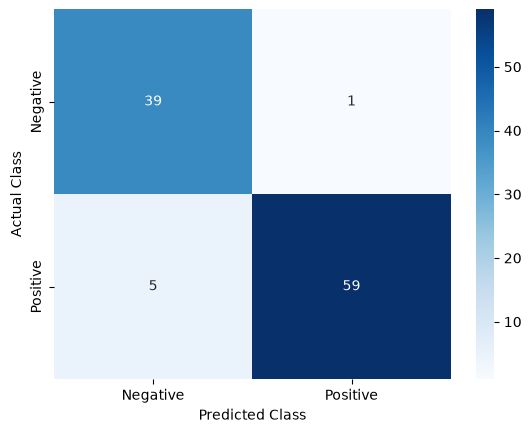

In [49]:
# Visualise the confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_class, y_pred_class)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


In [53]:
# Evaluation using K-fold cross-validation
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(model, X_class, y_class, cv=5)
print("Cross-validation scores: ", cv_scores)
print("Mean CV score: ", cv_scores.mean())

Cross-validation scores:  [0.89423077 0.93269231 0.875      0.97115385 0.95192308]
Mean CV score:  0.925


## **Regression**

In [1]:
import pandas as pd

# Load the datasets
red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")

# Combine both datasets
wine_df = pd.concat([red, white], ignore_index=True)

X_reg = wine_df.drop("quality", axis=1)
y_reg = wine_df["quality"]

In [31]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42)

In [ ]:
from sklearn.preprocessing import RobustScaler

# Scale the features using RobustScaler to reduce the impact of outliers
scaler = RobustScaler()
X_train_reg_scaled = scaler.fit_transform(X_train_reg)
X_test_reg_scaled = scaler.transform(X_test_reg)

In [18]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
# Fit the model using the scaled training data
lin_reg.fit(X_train_reg_scaled, y_train_reg)
# Make predictions on the scaled test data
y_pred_reg = lin_reg.predict(X_test_reg_scaled)

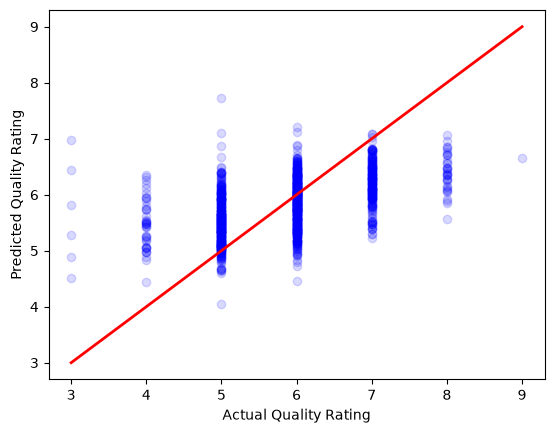

In [ ]:
import matplotlib.pyplot as plt

# Visualise the actual vs predicted quality ratings
plt.scatter(y_test_reg, y_pred_reg, color='blue', alpha=0.15)

# Add a line of best fit which represents good predictions (where predicted = actual)
plt.plot([y_test_reg.min(), y_test_reg.max()], 
         [y_test_reg.min(), y_test_reg.max()], 
         'r-', linewidth=2)

plt.xlabel('Actual Quality Rating')
plt.ylabel('Predicted Quality Rating')
plt.show()

In [44]:
from sklearn.metrics import mean_squared_error

# Calculate the mean squared error
mse = mean_squared_error(y_test_reg, y_pred_reg)
print("Mean Squared Error: {:.2f}".format(mse))

Mean Squared Error: 0.55


In [ ]:
# Evaluation using K-fold cross-validation
from sklearn.model_selection import cross_val_score

cv_scores_reg = cross_val_score(lin_reg, X_reg, y_reg, cv=5, scoring='neg_mean_squared_error')
# Convert negative MSE to positive values
cv_scores_reg = -cv_scores_reg
print("Cross-validation scores: ", cv_scores_reg)
print("Mean CV score: ", cv_scores_reg.mean())

Cross-validation scores (MSE):  [0.55074449 0.63107045 0.60470407 0.56539737 0.52257269]
Mean CV score (MSE):  0.5748978130221255
